# Angular Gini and Gini compared: sensitivity at the lower end

All distributions are constructed (no random samples, hence no dependence on a seed).
Indices as in the manuscript: Gini = Σ_{i<j} |yi−yj| / (n² μ); Angular Gini = Σ_{i<j} D_ij · ∠_ij with ∠_ij = (2/π)|atan2(yi,yj) − atan2(yj,yi)|;
Gastwirth = (1/n²) Σ_i Σ_j |yi−yj|/(yi+yj), with terms for yi = yj = 0 set to zero; Palma = share of the richest 10 % / share of the poorest 40 %; GE(α) with α = 0, 1, 2.

Experiments (manuscript Section 5; results are written to `output/`):
1. Constructed series (n = 20, mean 100): Table 6, `ag_comparison_series.csv`
2. Change of the poorest decile with all other incomes fixed (log-normal base, n = 200): Table 8, `ag_comparison_bottom_decile.csv`
3. Weight of a transfer between adjacent ranks relative to the Gini (log-normal base, n = 100): Section 5.3, `ag_comparison_transfer_weights.csv`
4. Same Gini, different shape of the distribution (n = 100): Table 7, `ag_comparison_equal_gini.csv`
5. Figure 3 of the manuscript (sensitivity curves, log-normal base with sigma = 1): `ag_comparison_curves_bottom_decile.csv`, `ag_comparison_transfer_profiles.csv`, `ag_comparison_fig_sensitivity.pdf` (and `.png`)

Requirements: numpy, pandas, scipy, matplotlib.

In [1]:
import os
import numpy as np
import pandas as pd
from scipy.stats import norm
from scipy.optimize import brentq

os.makedirs('output', exist_ok=True)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

def _pairs(y):
    y = np.asarray(y, float)
    return y, np.abs(y[:, None] - y[None, :]), y[:, None], y[None, :]

def gini(y):
    y, d, a, b = _pairs(y); n = len(y)
    return d.sum() / (2 * n**2 * y.mean())

def angular(y):
    y, d, a, b = _pairs(y); n = len(y)
    ang = (2 / np.pi) * np.abs(np.arctan2(a, b) - np.arctan2(b, a))
    return (d * ang).sum() / (2 * n**2 * y.mean())

def gastwirth(y):
    # pairs with y_i + y_j = 0 (both incomes zero) contribute 0
    y, d, a, b = _pairs(y); n = len(y); s = a + b
    with np.errstate(divide='ignore', invalid='ignore'):
        g = np.where(s > 0, d / s, 0.0)
    return g.sum() / n**2

def palma(y):
    y = np.sort(np.asarray(y, float)); n = len(y)
    p = np.arange(n + 1) / n
    L = np.concatenate([[0], np.cumsum(y)]) / y.sum()
    return (1 - np.interp(0.9, p, L)) / np.interp(0.4, p, L)

def ge(y, alpha):
    y = np.asarray(y, float); r = y / y.mean()
    if alpha == 0:
        return np.nan if (y <= 0).any() else -np.mean(np.log(r))
    if alpha == 1:
        return np.mean(np.where(r > 0, r * np.log(np.where(r > 0, r, 1)), 0.0))
    return np.mean(r**alpha - 1) / (alpha * (alpha - 1))

def all_idx(y):
    return {'Gini': gini(y), 'Angular Gini': angular(y), 'Gastwirth': gastwirth(y), 'Palma': palma(y),
            'GE(0)': ge(y, 0), 'GE(1)': ge(y, 1), 'GE(2)': ge(y, 2)}

def lognorm(n, sigma, mean=100.0):
    y = np.exp(sigma * norm.ppf((np.arange(1, n + 1) - 0.5) / n))
    return y * mean / y.mean()

# Check against numbers in the manuscript: Table 1 (Gini 0.400, Angular Gini 0.285) and y = (1, 2, 100): Gastwirth 0.505, Gini 0.641
print(round(gini([4, 8, 12, 36, 40]), 3), round(angular([4, 8, 12, 36, 40]), 3),
      round(gastwirth([1, 2, 100]), 3), round(gini([1, 2, 100]), 3))

0.4 0.285 0.505 0.641


In [2]:
# Experiment 1: constructed series (n = 20, mean 100)
n = 20
S = {
 'Equal incomes':                    np.full(n, 100.0),
 'Evenly spread (20 to 180)':        np.linspace(20, 180, n),
 'Two groups (50 and 150)':          np.r_[np.full(10, 50.), np.full(10, 150.)],
 'Poor bottom decile (2 x 10)':      np.r_[np.full(2, 10.), np.full(18, (2000 - 20) / 18)],
 'One zero income':                  np.r_[0., np.full(19, 2000 / 19)],
 'Four zero incomes (20 %)':         np.r_[np.zeros(4), np.full(16, 2000 / 16)],
 'Rich top (1 person, 43 %)':        np.r_[np.full(19, (2000 - 860) / 19), 860.],
 'Log-normal (sigma = 1)':           lognorm(n, 1.0),
}
E1 = pd.DataFrame({k: all_idx(v) for k, v in S.items()}).T
E1.index.name = 'Series'
E1.to_csv('output/ag_comparison_series.csv')
print(E1.to_string())

                              Gini  Angular Gini  Gastwirth  Palma   GE(0)  GE(1)  GE(2)
Series                                                                                  
Equal incomes               0.0000        0.0000     0.0000 0.2500 -0.0000 0.0000 0.0000
Evenly spread (20 to 180)   0.2800        0.1448     0.3054 0.8883  0.1578 0.1287 0.1179
Two groups (50 and 150)     0.2500        0.1476     0.2500 0.7500  0.1438 0.1308 0.1250
Poor bottom decile (2 x 10) 0.0900        0.0796     0.1500 0.3235  0.1445 0.0713 0.0450
One zero income             0.0500        0.0500     0.0950 0.2857     NaN 0.0513 0.0263
Four zero incomes (20 %)    0.2000        0.2000     0.3200 0.5000     NaN 0.2231 0.1250
Rich top (1 person, 43 %)   0.3800        0.3463     0.0826 1.9167  0.3777 0.6341 1.5200
Log-normal (sigma = 1)      0.4952        0.3533     0.4453 3.2622  0.4520 0.4191 0.5409


In [3]:
# Experiment 2: the poorest decile is multiplied by a factor, all other incomes stay fixed (log-normal base, n = 200)
names = list(all_idx(lognorm(10, 1)).keys())

def scale_bottom(y, frac, f):
    y = np.sort(np.asarray(y, float)); z = y.copy(); z[:int(round(frac * len(y)))] *= f; return z

rows = []
for sigma in [0.5, 1.0, 1.5]:
    y = lognorm(200, sigma); base = all_idx(y)
    for f in [0.5, 1.1, 1.5]:
        new = all_idx(scale_bottom(y, 0.10, f))
        rows.append({'sigma': sigma, 'Factor, poorest decile': f, **{k: 100 * (new[k] / base[k] - 1) for k in names}})
E2 = pd.DataFrame(rows)
E2.to_csv('output/ag_comparison_bottom_decile.csv', index=False)
print('Change of the indices in %'); print(E2.to_string(index=False))

Change of the indices in %
 sigma  Factor, poorest decile    Gini  Angular Gini  Gastwirth   Palma    GE(0)    GE(1)    GE(2)
0.5000                  0.5000  8.0836       20.1983    15.8481  9.0494  40.6587  21.4468  13.7170
0.5000                  1.1000 -1.5743       -3.1213    -2.5947 -1.6326  -4.6708  -3.1520  -2.3483
0.5000                  1.5000 -7.2246      -13.0360   -10.6662 -7.6626 -17.7299 -13.1336 -10.5136
1.0000                  0.5000  1.5456        3.0228     5.4394  5.6675  12.9273   3.4422   1.8438
1.0000                  1.1000 -0.3067       -0.5518    -0.9468 -1.0613  -1.7060  -0.6009  -0.3593
1.0000                  1.5000 -1.5005       -2.5981    -4.2385 -5.0905  -7.0883  -2.7966  -1.7656
1.5000                  0.5000  0.3149        0.5536     2.5886  3.5223   6.2233   0.6534   0.3361
1.5000                  1.1000 -0.0628       -0.1059    -0.4614 -0.6759  -0.8477  -0.1208  -0.0669
1.5000                  1.5000 -0.3114       -0.5142    -2.1131 -3.2905  -3.5873  

In [4]:
# Experiment 3: transfer of a small amount from rank k+1 to rank k (log-normal base, n = 100)
# Weight = (relative change of the Angular Gini) / (relative change of the Gini) for the same amount transferred
def pos_rel(y):
    y = np.sort(np.asarray(y, float)); mu = y.mean(); eps = 1e-6 * mu; a0, g0 = angular(y), gini(y)
    out = []
    for k in range(len(y) - 1):
        z = y.copy(); z[k] += eps; z[k + 1] -= eps
        out.append(((angular(z) - a0) / a0) / ((gini(z) - g0) / g0))
    return np.array(out)

E3 = pd.DataFrame({f'sigma = {s}': pos_rel(lognorm(100, s)) for s in [0.5, 1.0, 1.5]})
E3.index = np.arange(1, 100); E3.index.name = 'Rank k (transfer from rank k+1 to rank k)'
E3.to_csv('output/ag_comparison_transfer_weights.csv')
print(E3.loc[[1, 5, 10, 20, 40, 60, 80, 90, 99]].to_string())

                                           sigma = 0.5  sigma = 1.0  sigma = 1.5
Rank k (transfer from rank k+1 to rank k)                                       
1                                              18.3438      10.4995       6.8413
5                                               5.3983       4.1554       3.3710
10                                              3.3794       2.9210       2.5790
20                                              2.2015       2.1063       2.0048
40                                              1.5594       1.5863       1.5933
60                                              1.4217       1.4155       1.4268
80                                              1.6159       1.4339       1.3794
90                                              2.1013       1.6041       1.4358
99                                              7.4024       3.1204       2.0540


In [5]:
# Experiment 4: same Gini coefficient, different shape of the distribution (n = 100, mean 100)
def P(x):   # the poorest 20 % have the income x each, the other 80 % have equal incomes
    return np.r_[np.full(20, x), np.full(80, (10000 - 20 * x) / 80)]
def Q(T):   # one person has T, the other 99 have equal incomes
    return np.r_[np.full(99, (10000 - T) / 99), T]

rows = []
for x in [50, 30, 10]:
    gP = gini(P(x))
    T = brentq(lambda t: gini(Q(t)) - gP, 101, 9999)
    rows.append({'Pair': f'x = {x}', 'Distribution': f'P: poorest 20 % at {x} each', **all_idx(P(x))})
    rows.append({'Pair': f'x = {x}', 'Distribution': f'Q: one person at {T:,.0f}', **all_idx(Q(T))})
E4 = pd.DataFrame(rows)
E4.to_csv('output/ag_comparison_equal_gini.csv', index=False)
print(E4.to_string(index=False))

  Pair               Distribution   Gini  Angular Gini  Gastwirth  Palma  GE(0)  GE(1)  GE(2)
x = 50 P: poorest 20 % at 50 each 0.1000        0.0468     0.1231 0.3462 0.0444 0.0367 0.0312
x = 50     Q: one person at 1,100 0.1000        0.0896     0.0168 0.5309 0.0814 0.1690 0.5051
x = 30 P: poorest 20 % at 30 each 0.1400        0.0954     0.1898 0.3983 0.1118 0.0794 0.0613
x = 30     Q: one person at 1,500 0.1400        0.1298     0.0177 0.6618 0.1239 0.2766 0.9899
x = 10 P: poorest 20 % at 10 each 0.1800        0.1613     0.2717 0.4623 0.2982 0.1528 0.1013
x = 10     Q: one person at 1,900 0.1800        0.1701     0.0182 0.8056 0.1692 0.3969 1.6364


## Experiment 5: Figure 3 (sensitivity curves)

(a) Index relative to its baseline value when the incomes of the poorest decile are multiplied by a factor (log-normal base, sigma = 1, n = 200, mean 100, other incomes fixed).
(b) Relative weight of a small progressive transfer from rank k+1 to rank k (log-normal base, sigma = 1, n = 100): relative change of each index divided by the relative change of the Gini coefficient for the same transfer.
No random numbers are involved, so the figure is fully reproducible.

In [6]:
# Figure 3(a): curves for the poorest decile
grid = np.round(np.arange(0.25, 2.0001, 0.05), 2)
y0 = lognorm(200, 1.0); base0 = all_idx(y0)
show = ['Gini', 'Angular Gini', 'Gastwirth', 'Palma', 'GE(0)', 'GE(2)']
curves = pd.DataFrame({k: [100 * all_idx(scale_bottom(y0, 0.10, f))[k] / base0[k] for f in grid] for k in show}, index=grid)
curves.index.name = 'Factor, poorest decile'
curves.to_csv('output/ag_comparison_curves_bottom_decile.csv')
print(curves.loc[[0.25, 0.5, 1.0, 1.5, 2.0]].round(1).to_string())

                           Gini  Angular Gini  Gastwirth    Palma    GE(0)    GE(2)
Factor, poorest decile                                                             
0.2500                 102.3000      104.7000   108.7000 108.7000 126.4000 102.8000
0.5000                 101.5000      103.0000   105.4000 105.7000 112.9000 101.8000
1.0000                 100.0000      100.0000   100.0000 100.0000 100.0000 100.0000
1.5000                  98.5000       97.4000    95.8000  94.9000  92.9000  98.2000
2.0000                  97.1000       95.2000    92.7000  90.3000  88.2000  96.5000


In [7]:
# Figure 3(b): transfer weights of several indices (sigma = 1, n = 100)
def pos_rel_idx(y, fn):
    y = np.sort(np.asarray(y, float)); mu = y.mean(); eps = 1e-6 * mu; f0, g0 = fn(y), gini(y)
    out = []
    for k in range(len(y) - 1):
        z = y.copy(); z[k] += eps; z[k + 1] -= eps
        out.append(((fn(z) - f0) / f0) / ((gini(z) - g0) / g0))
    return np.array(out)

y1 = lognorm(100, 1.0)
prof = pd.DataFrame({
    'Angular Gini': pos_rel_idx(y1, angular),
    'GE(0)': pos_rel_idx(y1, lambda v: ge(v, 0)),
    'GE(1)': pos_rel_idx(y1, lambda v: ge(v, 1)),
    'GE(2)': pos_rel_idx(y1, lambda v: ge(v, 2)),
    'Gastwirth': pos_rel_idx(y1, gastwirth),
}, index=np.arange(1, 100))
prof.index.name = 'Rank k'
prof.to_csv('output/ag_comparison_transfer_profiles.csv')
print(prof.loc[[1, 5, 10, 20, 40, 60, 80, 90, 99]].round(2).to_string())
print('Gastwirth: smallest weight', round(float(prof['Gastwirth'].min()), 3), '| number of negative weights:', int((prof['Gastwirth'] < 0).sum()))

        Angular Gini    GE(0)   GE(1)   GE(2)  Gastwirth
Rank k                                                  
1            10.5000 376.5100 22.1300  0.8600    65.7400
5             4.1600  43.3500  5.3000  0.4200    18.2400
10            2.9200  17.6500  3.1100  0.3600    10.2000
20            2.1100   7.1200  1.9500  0.3500     5.2000
40            1.5900   2.8600  1.4100  0.4500     2.0400
60            1.4200   1.7300  1.4100  0.7500     0.7200
80            1.4300   1.3200  1.9500  1.8800    -0.1300
90            1.6000   1.3600  3.1100  4.6500    -0.5800
99            3.1200   3.2700 22.1300 99.2100    -1.9200
Gastwirth: smallest weight -1.924 | number of negative weights: 23


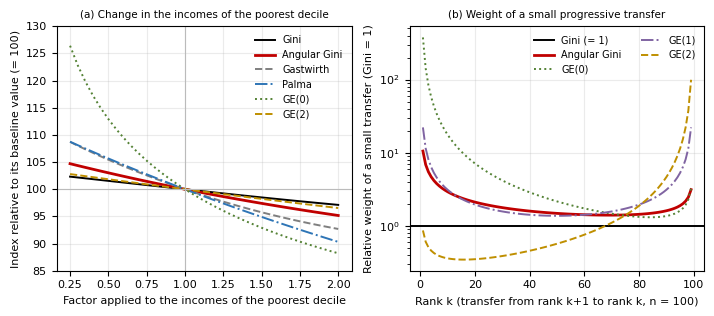

Figure saved


In [8]:
# Figure 3: save as PDF (for the manuscript) and PNG
import matplotlib.pyplot as plt

with plt.rc_context({'font.size': 8, 'axes.titlesize': 8.5, 'legend.fontsize': 7}):
    styles = {'Gini': ('black', '-'), 'Angular Gini': ('#C00000', '-'), 'Gastwirth': ('#7F7F7F', '--'),
              'Palma': ('#2E75B6', '-.'), 'GE(0)': ('#548235', ':'), 'GE(2)': ('#BF8F00', '--')}
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.2))
    for k in show:
        c, ls = styles[k]
        ax[0].plot(curves.index, curves[k], color=c, ls=ls, lw=2.0 if k == 'Angular Gini' else 1.4, label=k)
    ax[0].axhline(100, color='#BBBBBB', lw=0.8); ax[0].axvline(1, color='#BBBBBB', lw=0.8)
    ax[0].set_xlabel('Factor applied to the incomes of the poorest decile')
    ax[0].set_ylabel('Index relative to its baseline value (= 100)')
    ax[0].set_title('(a) Change in the incomes of the poorest decile', fontsize=7.5)
    ax[0].legend(fontsize=7, frameon=False); ax[0].set_ylim(85, 130)

    pstyles = {'Angular Gini': ('#C00000', '-'), 'GE(0)': ('#548235', ':'), 'GE(1)': ('#8064A2', '-.'), 'GE(2)': ('#BF8F00', '--')}
    ax[1].axhline(1, color='black', lw=1.4, label='Gini (= 1)')
    for k, (c, ls) in pstyles.items():
        ax[1].plot(prof.index, prof[k], color=c, ls=ls, lw=2.0 if k == 'Angular Gini' else 1.4, label=k)
    ax[1].set_yscale('log'); ax[1].set_xlabel('Rank k (transfer from rank k+1 to rank k, n = 100)')
    ax[1].set_ylabel('Relative weight of a small transfer (Gini = 1)')
    ax[1].set_title('(b) Weight of a small progressive transfer', fontsize=7.5)
    ax[1].legend(fontsize=7, frameon=False, ncol=2)
    for a in ax: a.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig('output/ag_comparison_fig_sensitivity.pdf'); fig.savefig('output/ag_comparison_fig_sensitivity.png', dpi=130)
    plt.show()
print('Figure saved')